# The Canadian Curve Through the Bank of Canada's Hiking and Cutting Cycle

The swap notebook values one swap on one day. Here I look at how the Canadian government curve has moved since 2022 and what it is pricing now. The notebook downloads fresh data every time it runs, so it also works as a simple rates monitor.

In this notebook I:
1. Download the policy rate, 2, 5 and 10-year yields and inflation from the Bank of Canada.
2. Follow the 2-year yield and the curve shape (2s10s and the 2s5s10s butterfly) through the cycle.
3. Compare the 2-year yield with the policy rate to see what the market expects.
4. Put the latest numbers in one table that can be rerun as a simple monitor.

All data comes from the Bank of Canada Valet API. Yields are in percent, spreads in basis points (bp).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests

START = "2022-01-01"

def get_series(names, start=START):
    url = f"https://www.bankofcanada.ca/valet/observations/{','.join(names)}/json"
    obs = requests.get(url, params={"start_date": start}, timeout=30).json()["observations"]
    rows = [{"date": o["d"], **{n: o[n]["v"] if n in o else None for n in names}} for o in obs]
    return pd.DataFrame(rows).set_index("date").apply(pd.to_numeric).rename_axis(None)

rates = get_series(["V39079", "BD.CDN.2YR.DQ.YLD", "BD.CDN.5YR.DQ.YLD", "BD.CDN.10YR.DQ.YLD"])
rates.columns = ["policy", "y2", "y5", "y10"]
rates.index = pd.to_datetime(rates.index)
rates["policy"] = rates["policy"].ffill()          # the policy rate only has a value on announcement days
rates = rates.dropna(subset=["y2", "y5", "y10"])

cpi = get_series(["STATIC_TOTALCPICHANGE", "CPI_TRIM", "CPI_MEDIAN"])
cpi.columns = ["headline", "trim", "median"]
cpi.index = pd.to_datetime(cpi.index)

print(f"Yields: {rates.index[0].date()} to {rates.index[-1].date()} ({len(rates)} days)")
print(f"CPI:    {cpi.index[0]:%b %Y} to {cpi.dropna().index[-1]:%b %Y}")
rates.tail()

Yields: 2022-01-04 to 2026-11-04 (1206 days)
CPI:    Jan 2022 to Sep 2026


,policy,y2,y5,y10
2026-10-29,2.5,3.36,3.58,3.84
2026-10-30,2.5,3.28,3.51,3.78
2026-11-02,2.5,3.26,3.46,3.74
2026-11-03,2.5,3.26,3.49,3.77
2026-11-04,2.5,3.22,3.43,3.70


## 1. The policy cycle

First, the Bank of Canada's decisions. The policy rate is the overnight rate target.

In [2]:
changes = rates["policy"][rates["policy"].diff() != 0].iloc[1:]
moves = pd.DataFrame({"rate": changes, "move_bp": (changes.diff().fillna(changes.iloc[0] - 0.25) * 100).round()})
moves.index = moves.index.date
print(moves.to_string())
print(f"\nPeak: {rates['policy'].max():.2f}%   Low after cuts: {rates.loc['2024':, 'policy'].min():.2f}%   Now: {rates['policy'].iloc[-1]:.2f}%")

            rate  move_bp
2022-03-03  0.50     25.0
2022-04-14  1.00     50.0
2022-06-02  1.50     50.0
2022-07-14  2.50    100.0
2022-09-08  3.25     75.0
2022-10-27  3.75     50.0
2022-12-08  4.25     50.0
2023-01-26  4.50     25.0
2023-06-08  4.75     25.0
2023-07-13  5.00     25.0
2024-06-06  4.75    -25.0
2024-07-25  4.50    -25.0
2024-09-05  4.25    -25.0
2024-10-24  3.75    -50.0
2024-12-12  3.25    -50.0
2025-01-30  3.00    -25.0
2025-03-13  2.75    -25.0
2025-09-18  2.50    -25.0
2025-10-30  2.25    -25.0
2026-10-29  2.50     25.0

Peak: 5.00%   Low after cuts: 2.25%   Now: 2.50%


The Bank hiked from 0.25% to 5.00% between March 2022 and July 2023, held for almost a year, then cut nine times to 2.25% by October 2025. On October 29, 2026 it hiked again to 2.50%, the first hike since 2023.

The 2-year yield moves ahead of the policy rate because it reflects where the market expects the rate to be over the next two years.

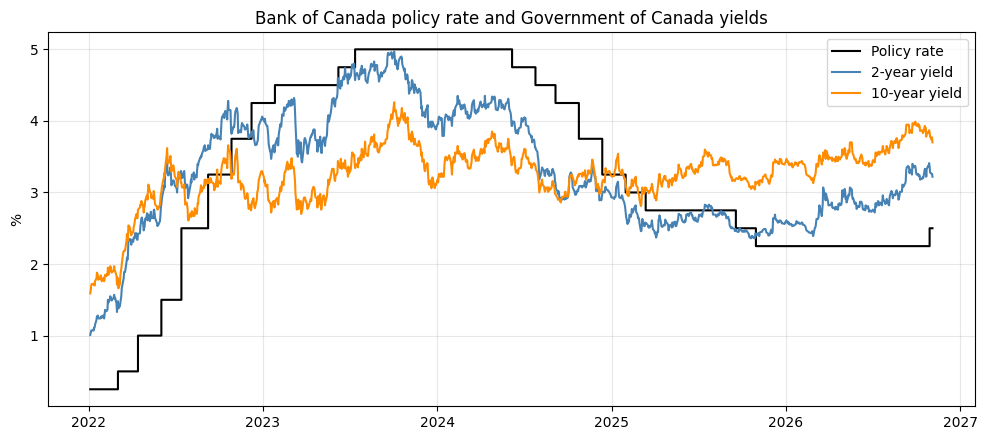

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.step(rates.index, rates["policy"], where="post", color="black", label="Policy rate")
ax.plot(rates.index, rates["y2"], color="steelblue", label="2-year yield")
ax.plot(rates.index, rates["y10"], color="darkorange", label="10-year yield")
ax.set(title="Bank of Canada policy rate and Government of Canada yields", ylabel="%")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/04_policy_and_yields.png", dpi=150); plt.show()

## 2. The shape of the curve

Two common ways to describe the shape:
- **2s10s** = 10-year yield − 2-year yield. Negative means the curve is inverted.
- **2s5s10s butterfly** = 2 × 5-year − 2-year − 10-year. Positive means the 5-year is high compared with the two ends.

Deepest inversion: -132bp on 2023-06-30
2s10s positive again from: 2024-09-19


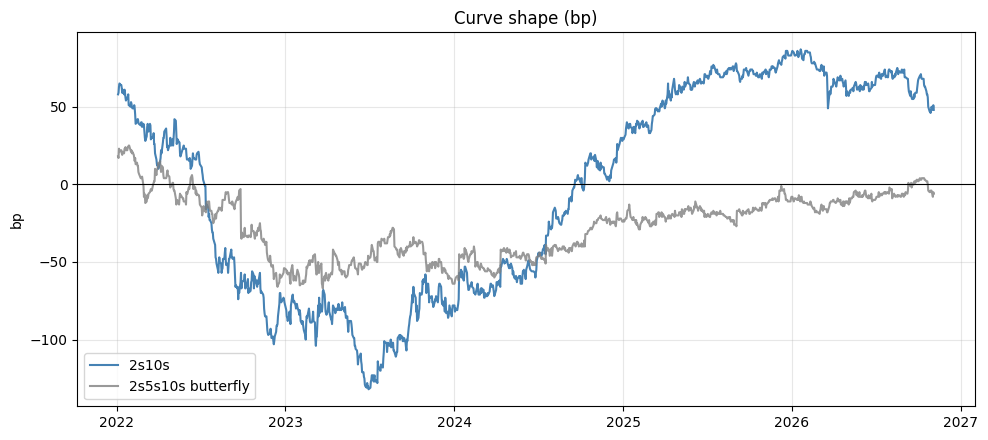

In [4]:
rates["s2s10"] = (rates["y10"] - rates["y2"]) * 100
rates["fly"] = (2 * rates["y5"] - rates["y2"] - rates["y10"]) * 100

low = rates["s2s10"].idxmin()
back_positive = rates.loc[low:].query("s2s10 > 0").index[0]
print(f"Deepest inversion: {rates.loc[low, 's2s10']:.0f}bp on {low.date()}")
print(f"2s10s positive again from: {back_positive.date()}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rates.index, rates["s2s10"], color="steelblue", label="2s10s")
ax.plot(rates.index, rates["fly"], color="gray", alpha=0.8, label="2s5s10s butterfly")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Curve shape (bp)", ylabel="bp")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/05_curve_shape.png", dpi=150); plt.show()

The hikes inverted the curve. The 2-year rose much faster than the 10-year, and 2s10s reached about −130bp in mid-2023. The curve only turned positive again in September 2024, after the cuts had started. In a cutting cycle the front end usually falls fastest, which is what steepened the curve through 2024 and 2025.

## 3. Inflation

Headline CPI includes volatile items like gasoline. The Bank of Canada's preferred core measures, CPI-trim and CPI-median, remove the most extreme price changes each month.

            headline  trim  median
2026-04-01       2.8   2.0     2.1
2026-05-01       3.2   2.0     2.1
2026-06-01       2.8   1.9     1.9
2026-07-01       3.0   1.9     2.0
2026-08-01       3.0   1.9     2.0
2026-09-01       3.1   1.8     1.9


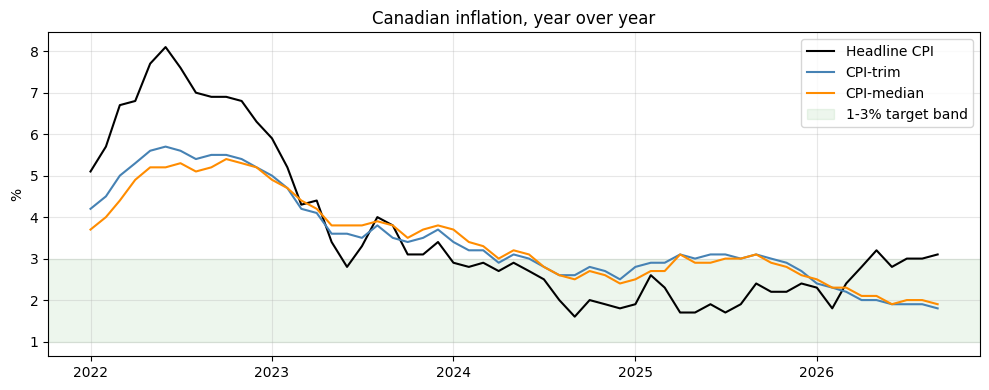

In [5]:
print(cpi.dropna().tail(6).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cpi.index, cpi["headline"], color="black", label="Headline CPI")
ax.plot(cpi.index, cpi["trim"], color="steelblue", label="CPI-trim")
ax.plot(cpi.index, cpi["median"], color="darkorange", label="CPI-median")
ax.axhspan(1, 3, color="green", alpha=0.07, label="1-3% target band")
ax.set(title="Canadian inflation, year over year", ylabel="%")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/06_inflation.png", dpi=150); plt.show()

Headline inflation has been around 3% since mid-2026, at the top of the target band, while both core measures are around 2% or below. So the pressure is in the volatile parts of the basket, not in underlying inflation.

## 4. What the market is pricing

If the 2-year yield is above the policy rate, the market expects the policy rate to be higher on average over the next two years. This is only a rough guide, because the 2-year yield also includes a term premium, but the gap is a simple way to read expectations.

In [6]:
rates["y2_vs_policy"] = (rates["y2"] - rates["policy"]) * 100
dates = ["2025-10-22", "2026-03-02", "2026-06-01", "2026-09-01", "2026-10-21"]
snap = pd.concat([rates.loc[:d].iloc[-1] for d in dates] + [rates.iloc[-1]], axis=1).T
snap.index = [d for d in dates] + [str(rates.index[-1].date())]
print(snap[["policy", "y2", "y5", "y10", "s2s10", "fly", "y2_vs_policy"]].round(2).to_string())

last = rates.iloc[-1]
print("\nChange to the latest date (bp):")
for months, label in [(1, "1 month"), (3, "3 months"), (12, "1 year")]:
    prev = rates.loc[:rates.index[-1] - pd.DateOffset(months=months)].iloc[-1]
    print(f"  {label:>8}: 2y {(last.y2 - prev.y2) * 100:+.0f}   10y {(last.y10 - prev.y10) * 100:+.0f}   2s10s {last.s2s10 - prev.s2s10:+.0f}")

            policy    y2    y5   y10  s2s10   fly  y2_vs_policy
2025-10-22    2.50  2.38  2.64  3.07   69.0 -17.0         -12.0
2026-03-02    2.25  2.49  2.76  3.22   73.0 -19.0          24.0
2026-06-01    2.25  2.81  3.08  3.43   62.0  -8.0          56.0
2026-09-01    2.25  3.01  3.35  3.75   74.0  -6.0          76.0
2026-10-21    2.25  3.32  3.62  3.90   58.0   2.0         107.0
2026-11-04    2.50  3.22  3.43  3.70   48.0  -6.0          72.0

Change to the latest date (bp):
   1 month: 2y -3   10y -23   2s10s -20
  3 months: 2y +39   10y +15   2s10s -24
    1 year: 2y +79   10y +55   2s10s -24


Over the past year the 2-year rose about 80bp and the 10-year about 55bp, so the curve **bear flattened** by about 25bp. Before the October hike the 2-year was more than 100bp above the policy rate. After the hike the 2-year fell, but it is still about 70bp above the new 2.50% rate, which means the market still expects more hikes.

## 5. Monitor table

The numbers I would check after each data release or Bank of Canada decision. Rerunning the notebook updates them.

In [7]:
cpi_last = cpi.dropna().iloc[-1]
cpi_month = f"{cpi.dropna().index[-1]:%b %Y}"
monitor = pd.Series({
    "Date": str(rates.index[-1].date()),
    "Policy rate (%)": last.policy,
    "2-year yield (%)": last.y2,
    "10-year yield (%)": last.y10,
    "2s10s (bp)": round(last.s2s10),
    "2s5s10s butterfly (bp)": round(last.fly),
    "2-year minus policy rate (bp)": round(last.y2_vs_policy),
    f"Headline CPI, {cpi_month} (%)": cpi_last["headline"],
    f"CPI-trim, {cpi_month} (%)": cpi_last["trim"],
    f"CPI-median, {cpi_month} (%)": cpi_last["median"],
})
print(monitor.to_string())

Date                             2026-11-04
Policy rate (%)                         2.5
2-year yield (%)                       3.22
10-year yield (%)                       3.7
2s10s (bp)                               48
2s5s10s butterfly (bp)                   -6
2-year minus policy rate (bp)            72
Headline CPI, Sep 2026 (%)              3.1
CPI-trim, Sep 2026 (%)                  1.8
CPI-median, Sep 2026 (%)                1.9


## 6. What I would watch

I am not taking a view here, but the data points to a few open questions:
- **Core inflation.** Headline CPI is near 3% while CPI-trim and CPI-median are near 2%. If the core measures start rising, the case for more hikes gets stronger.
- **The 2-year against the policy rate.** The gap is about 70bp after the hike. If it narrows, the market is pricing fewer hikes.
- **The curve.** 2s10s has flattened by about 25bp over the past year, because the 2-year rose more than the 10-year.

## 7. Limitations

- These are government bond yields, not swap rates. Canadian swaps are priced off CORRA and trade at a spread to these yields.
- The 2-year minus policy rate gap includes a term premium, so it is only a rough guide to the hikes priced.
- The 10-year is also driven by US yields, which this notebook does not include.
- CPI is published monthly with a lag, so it is always a month or more behind the yields.